# PharmaValuate - single notebook (screening aid, genuine-only detectors)
Sections: **0 setup** | **1 data + manifest** | **2 segment + split** | **3 synthetic tampers** | **4 quality gate** | **5 product ID** | **6 detectors (AnomalyDINO, PatchCore, EfficientAD)** | **7 supervised reference** | **8 calibrate + freeze** | **9 FINAL TEST (guarded)** | **10 plots**

Rules (same as AGENTS.md): never tune on test; fakes are *synthetic stress tests* only; wording = "screening only, verify manually". Every stage skips itself if its output file already exists, so a crash costs nothing. Delete the output file to force a re-run.
Pill data = real NLM C3PI/RxImage in `data/raw/c3pi_full` (reference gallery from `rximage.zip`, phone-style consumer photos downloaded per file).
Dropped from the old 15 notebooks: env check (now 1 cell), OCR rules, cost/latency, MVTec sanity, perturbation set.

## 0. Setup

In [16]:
import sys, os, json, time, glob, re, zlib, pathlib, shutil, itertools
sys.path.insert(0, os.path.abspath(".."))
from pv.config import *
import numpy as np, pandas as pd, cv2, torch, yaml
import matplotlib.pyplot as plt
from tqdm import tqdm

# ---------------- SETTINGS ----------------
STREAM = "pill"            # "pill" or "pack"  (finish pill first)
PACK_CASE = "B"            # pack only: "B" = Italian-OTC reference + degraded phone-style variants
RUN_EFFICIENTAD = True     # slowest part; set False to skip
EFFAD_SIZE, EFFAD_STEPS, SEED = "S", 15000, 0     # 15000 = first pass, 70000 = final
RUN_SUPERVISED = True
I_FROZE_EVERYTHING = True # only True after section 8 wrote configs/frozen.yaml and you committed it
CONSUMER_LAYOUT = "MC_CHALLENGE_V1.0"   # pill only: which consumer-photo layout of the NLM directory file counts as 'phone'
MAX_PER_PRODUCT, MAX_PRODUCTS = 20, 600   # images kept per product & domain / products kept in total
# Changing any of the three data settings above (or this tag) moves the old outputs of the stream to stale/ and starts clean
DATA_VERSION = f"c3pi_full|{CONSUMER_LAYOUT}|{MAX_PER_PRODUCT}|{MAX_PRODUCTS}|v1"
# ------------------------------------------
def have(p): return pathlib.Path(p).exists()
for d in (PROC, SPLITS, SCORES, SYNTH, RES / "tables", RES / "figures", RES / "retrieval", ROOT / "configs", ROOT / "models"): d.mkdir(parents=True, exist_ok=True)
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available(): print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB")
seed_everything(0)

torch 2.6.0+cu124 | cuda available: True
NVIDIA GeForce RTX 4060 Laptop GPU 8.0 GB


In [17]:
# Stale-output guard. Every stage skips itself when its output exists, so outputs left over from the old 27-image
# sample runs would silently poison this run. Anything of this stream that was made with a different DATA_VERSION is MOVED
# (not deleted) to stale/<stream>_<timestamp>/. Same DATA_VERSION -> nothing happens, so a crashed run resumes normally.
def archive_stale(stream):
    marker = PROC / f"{stream}_data_version.txt"
    if marker.exists() and marker.read_text().strip() == DATA_VERSION:
        print("outputs match DATA_VERSION - resuming"); return
    old = [PROC / f"{stream}_raw_manifest.csv", PROC / stream, SPLITS / f"{stream}_splits.csv", SPLITS / f"{stream}_all.csv", SYNTH / stream, ROOT / "data" / "anomalib" / stream]
    old += list(SCORES.glob(f"*__{stream}__*.csv")) + list((RES / "tables").glob(f"*_{stream}*.csv")) + list((RES / "retrieval").glob(f"{stream}_*.csv"))
    old += list((ROOT / "configs").glob(f"*_{stream}*.json")) + list((ROOT / "models").glob(f"*_{stream}_*"))
    old = [p for p in old if p.exists()]
    if old:
        dest = ROOT / "stale" / f"{stream}_{time.strftime('%Y%m%d_%H%M%S')}"
        for p in old:
            try: rel = p.relative_to(ROOT)
            except ValueError: rel = pathlib.Path(p.name)
            (dest / rel).parent.mkdir(parents=True, exist_ok=True); shutil.move(str(p), str(dest / rel))
        print(f"moved {len(old)} old output(s) of stream '{stream}' to {dest}")
    else: print("no old outputs found - clean start")
    marker.write_text(DATA_VERSION)
archive_stale(STREAM)

outputs match DATA_VERSION - resuming


## 1. Data audit + manifest
**Reference gallery** = `data/raw/c3pi_full/extracted/image/images/gallery/original` (from `rximage.zip`). **Phone-style images** = the `CONSUMER_LAYOUT` rows of `directory_consumer_grade_images.xlsx`, downloaded file by file into `data/raw/c3pi_full/consumer/` (resumes if interrupted; already downloaded files are skipped).
Only products that have **both** reference and phone images are kept. Product id = NDC labeler-product (`63459-0502`), taken from the NDC column / the reference file names, never from folder names.
The manifest check in the next cell refuses to continue below 30 products / 150 phone images / 10 products with both. Do not lower those thresholds.

In [18]:
import urllib.request, urllib.parse
from concurrent.futures import ThreadPoolExecutor
IMG_EXT = {".jpg", ".jpeg", ".png"}          # .cr2 raw files are skipped on purpose
def imgs(root): return [p for p in pathlib.Path(root).rglob("*") if p.suffix.lower() in IMG_EXT and ".cache" not in p.parts]
NDC = re.compile(r"(\d{4,5})-(\d{3,4})")
def norm_ndc(x):
    m = NDC.search(str(x)); return f"{m.group(1).zfill(5)}-{m.group(2).zfill(4)}" if m else None

C3 = ROOT / "data/raw/c3pi_full"; SITE = "https://data.lhncbc.nlm.nih.gov/public/Pills/"
GALLERY = C3 / "extracted/image/images/gallery/original"; DIRECTORY_XLSX = C3 / "directory_consumer_grade_images.xlsx"
SEL_CSV = C3 / f"consumer_selected_{CONSUMER_LAYOUT}.csv"

def select_consumer():
    d = pd.read_excel(DIRECTORY_XLSX, dtype=str)                       # NDC11 loses its leading zeros in the file -> zfill
    d["ndc11"] = d["NDC11"].str.zfill(11); d["product_id"] = d.ndc11.str[:5] + "-" + d.ndc11.str[5:9]
    d = d[(d.Layout == CONSUMER_LAYOUT) & d.Image.str.lower().str.endswith((".jpg", ".jpeg", ".png"))].drop_duplicates("Image")
    d.to_csv(SEL_CSV, index=False); return d

def download(rel_paths, workers=8):
    def get(rel):
        dst = C3 / "consumer" / rel
        if dst.exists() and dst.stat().st_size > 0: return rel, True
        dst.parent.mkdir(parents=True, exist_ok=True)
        for k in range(4):
            try:
                with urllib.request.urlopen(SITE + urllib.parse.quote(rel), timeout=60) as r: data = r.read()
                tmp = str(dst) + ".part"
                with open(tmp, "wb") as f: f.write(data)
                os.replace(tmp, dst); return rel, True
            except Exception: time.sleep(2 * (k + 1))
        return rel, False
    failed, done = [], 0
    with ThreadPoolExecutor(workers) as ex:
        for rel, ok in ex.map(get, rel_paths):
            done += 1; failed += [] if ok else [rel]
            if done % 500 == 0: print(f"  {done}/{len(rel_paths)} downloaded, {len(failed)} failed")
    return failed

if have(PROC / f"{STREAM}_raw_manifest.csv"):
    df = pd.read_csv(PROC / f"{STREAM}_raw_manifest.csv"); print("loaded existing manifest", len(df))
elif STREAM == "pill":
    sel = pd.read_csv(SEL_CSV, dtype=str) if have(SEL_CSV) else select_consumer()
    sel["path"] = [str(C3 / "consumer" / r) for r in sel.Image]
    todo = [r for r, p in zip(sel.Image, sel.path) if not os.path.exists(p)]
    if todo: print(f"downloading {len(todo)} of {len(sel)} consumer images (resumable) ..."); print("failed:", len(download(todo)))
    ok = sel.path.map(os.path.exists); print(f"consumer images on disk: {int(ok.sum())} of {len(sel)}")
    assert ok.mean() > 0.98, "more than 2% of the consumer images are missing - re-run this cell to retry the download (check your internet connection)"
    sel = sel[ok]; ref = imgs(GALLERY); assert len(ref) > 0, f"no reference images found under {GALLERY} - check the extraction of rximage.zip"
    rows = [dict(path=p, product_id=pid, domain="phone") for p, pid in zip(sel.path, sel.product_id)]
    rows += [dict(path=str(p), product_id=norm_ndc(p.name), domain="ref") for p in ref]
    df = pd.DataFrame(rows); n0 = len(df); df = df.dropna(subset=["product_id"]); print(f"reference images: {len(ref)} | no NDC in name, dropped: {n0 - len(df)}")
    both = set(df[df.domain == "phone"].product_id) & set(df[df.domain == "ref"].product_id)
    print(f"products: {df[df.domain == 'phone'].product_id.nunique()} with phone images, {df[df.domain == 'ref'].product_id.nunique()} with reference images, {len(both)} with BOTH (kept)")
    df = df[df.product_id.isin(both)].reset_index(drop=True)
else:
    SRC = ROOT / ("data/raw/italian_otc" if PACK_CASE == "B" else "data/raw/mendeley")
    df = pd.DataFrame({"path": [str(p) for p in imgs(SRC)]}); df["product_id"] = [pathlib.Path(p).parent.name for p in df.path]; df["domain"] = "ref" if PACK_CASE == "B" else "phone"
    print("pack: product = parent folder name - open a few files and confirm this is right for your data")
if not have(PROC / f"{STREAM}_raw_manifest.csv"):
    df = df.groupby(["product_id", "domain"]).head(MAX_PER_PRODUCT)
    keep = df.product_id.drop_duplicates().sample(min(MAX_PRODUCTS, df.product_id.nunique()), random_state=0); df = df[df.product_id.isin(keep)].reset_index(drop=True)
print(df.domain.value_counts().to_dict(), df.product_id.nunique(), "products")

loaded existing manifest 2544
{'phone': 1280, 'ref': 1264} 600 products


In [19]:
def check_manifest(m, stream=STREAM):
    probs = []
    if m.product_id.nunique() < 30: probs.append(f"only {m.product_id.nunique()} products (need >= 30)")
    if stream == "pill":
        ph, rf = m[m.domain == "phone"], m[m.domain == "ref"]; both = set(ph.product_id) & set(rf.product_id)
        if len(ph) < 150: probs.append(f"only {len(ph)} phone images (need >= 150)")
        if len(both) < 10: probs.append(f"only {len(both)} products have both reference and phone images (need >= 10)")
        if (~m.product_id.astype(str).str.match(r"^\d{5}-\d{4}$")).any(): probs.append("some product ids are not NDC-style (folder names leaking in?)")
    if probs: raise SystemExit("MANIFEST CHECK FAILED - get more/correct data, do not lower thresholds:\n  - " + "\n  - ".join(probs))
    print("manifest check passed")
check_manifest(df)

manifest check passed


In [20]:
import imagehash
from PIL import Image
if "group_id" not in df:
    df["ph"] = [imagehash.phash(Image.open(p).convert("RGB")) for p in tqdm(df.path)]
    gid = np.empty(len(df), dtype=object)
    for pid, g in df.groupby("product_id"):
        idx = g.index.to_list(); parent = {i: i for i in idx}
        def find(i):
            while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
            return i
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                if df.ph[idx[a]] - df.ph[idx[b]] <= 6: parent[find(idx[a])] = find(idx[b])
        for i in idx: gid[i] = f"{pid}_g{find(i)}"
    df["group_id"] = gid; df["stream"] = STREAM
    df.drop(columns="ph").to_csv(PROC / f"{STREAM}_raw_manifest.csv", index=False)
    sizes = [Image.open(p).size for p in df.path.sample(min(200, len(df)), random_state=0)]
    pd.DataFrame([dict(stream=STREAM, n_images=len(df), n_products=df.product_id.nunique(), n_groups=df.group_id.nunique(),
        median_w=int(np.median([s[0] for s in sizes])), median_h=int(np.median([s[1] for s in sizes])))]).to_csv(RES / "tables" / f"audit_{STREAM}.csv", index=False)
m = pd.read_csv(PROC / f"{STREAM}_raw_manifest.csv"); print(len(m), "rows,", m.group_id.nunique(), "groups")

2544 rows, 2434 groups


## 2. Segment, crop, split, leakage audit

In [21]:
from pv.splits import make_splits, assert_no_leak
OUT = PROC / STREAM; (OUT / "clean").mkdir(parents=True, exist_ok=True); (OUT / "mask").mkdir(exist_ok=True)
def grabcut_mask(im):
    h, w = im.shape[:2]; s = 512 / max(h, w); sm = cv2.resize(im, None, fx=s, fy=s) if s < 1 else im.copy()
    mask = np.zeros(sm.shape[:2], np.uint8); H, W = sm.shape[:2]; rect = (int(W*.05), int(H*.05), int(W*.9), int(H*.9))
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    try: cv2.grabCut(cv2.cvtColor(sm, cv2.COLOR_RGB2BGR), mask, rect, bgd, fgd, 4, cv2.GC_INIT_WITH_RECT)
    except cv2.error: mask[:] = 3
    fg = ((mask == 1) | (mask == 3)).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(fg)
    if n > 1: fg = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    return cv2.resize(fg, (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
def crop_square(im, mask, size=512, margin=0.08):
    ys, xs = np.where(mask)
    if len(ys) < 50: ys, xs = np.array([0, im.shape[0]-1]), np.array([0, im.shape[1]-1]); mask = np.ones_like(mask)
    y0, y1, x0, x1 = ys.min(), ys.max()+1, xs.min(), xs.max()+1; side = int(max(y1-y0, x1-x0)*(1+2*margin)); cy, cx = (y0+y1)//2, (x0+x1)//2; pad = side
    imp = cv2.copyMakeBorder(im, pad, pad, pad, pad, cv2.BORDER_REPLICATE); mp = cv2.copyMakeBorder(mask.astype(np.uint8), pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    ya, xa = cy - side//2 + pad, cx - side//2 + pad; c, cm = imp[ya:ya+side, xa:xa+side], mp[ya:ya+side, xa:xa+side]
    return cv2.resize(c, (size, size), interpolation=cv2.INTER_AREA), cv2.resize(cm, (size, size), interpolation=cv2.INTER_NEAREST) > 0
def degrade(im, rng):    # pack Case B: phone-style genuine variants from clean reference images
    im = im.astype(np.float32); M = cv2.getRotationMatrix2D((im.shape[1]/2, im.shape[0]/2), rng.uniform(-12, 12), rng.uniform(.95, 1.05)); im = cv2.warpAffine(im, M, im.shape[1::-1], borderMode=cv2.BORDER_REPLICATE)
    im = cv2.GaussianBlur(im, (0, 0), rng.uniform(0, 1.6)); im = im * rng.uniform(.7, 1.25) + rng.uniform(-18, 18)
    if rng.random() < .3:
        g = np.zeros(im.shape[:2], np.float32); cv2.circle(g, (int(rng.integers(0, im.shape[1])), int(rng.integers(0, im.shape[0]))), int(rng.integers(20, 60)), 1, -1); im += cv2.GaussianBlur(g, (0, 0), 25)[..., None] * rng.uniform(40, 110)
    im += rng.normal(0, rng.uniform(0, 5), im.shape); return np.clip(im, 0, 255).astype(np.uint8)
N_VARIANTS = 6
if not have(SPLITS / f"{STREAM}_splits.csv"):
    rows = []; rng = np.random.default_rng(0)
    for i, r in tqdm(m.iterrows(), total=len(m)):
        im = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB); c, cm = crop_square(im, grabcut_mask(im)); base = f"{i:06d}"
        cv2.imwrite(str(OUT/"clean"/f"{base}.png"), cv2.cvtColor(c, cv2.COLOR_RGB2BGR)); cv2.imwrite(str(OUT/"mask"/f"{base}.png"), cm.astype(np.uint8)*255)
        rows.append(dict(path=str(OUT/"clean"/f"{base}.png"), obj_mask=str(OUT/"mask"/f"{base}.png"), product_id=r.product_id, group_id=r.group_id, domain=r.domain, stream=STREAM))
        if STREAM == "pack" and PACK_CASE == "B":
            for k in range(N_VARIANTS):
                v = degrade(c, rng); vb = f"{base}_v{k}"
                cv2.imwrite(str(OUT/"clean"/f"{vb}.png"), cv2.cvtColor(v, cv2.COLOR_RGB2BGR)); cv2.imwrite(str(OUT/"mask"/f"{vb}.png"), cm.astype(np.uint8)*255)
                rows.append(dict(path=str(OUT/"clean"/f"{vb}.png"), obj_mask=str(OUT/"mask"/f"{vb}.png"), product_id=r.product_id, group_id=f"{r.product_id}_var{k//2}", domain="phone", stream=STREAM))
    proc = pd.DataFrame(rows)
    sp = make_splits(proc, CFG["unknown_fraction"], CFG["split_fractions"]["val"], CFG["split_fractions"]["cal"], seed=0)
    assert_no_leak(sp); sp.to_csv(SPLITS / f"{STREAM}_splits.csv", index=False)
sp = pd.read_csv(SPLITS / f"{STREAM}_splits.csv"); print(sp.split.value_counts()); print(sp.groupby(["split", "domain"]).size())

split
gallery         1016
test             619
cal              260
unknown_test     252
unknown_val      246
val              151
Name: count, dtype: int64
split         domain
cal           phone      260
gallery       ref       1016
test          phone      619
unknown_test  phone      126
              ref        126
unknown_val   phone      124
              ref        122
val           phone      151
dtype: int64


## 3. Synthetic tampers + identical JPEG re-encode of ALL images (stress-test fakes; never used to train detectors)

split         label
cal           0         260
              1         780
gallery       0        1016
test          0         619
              1        1857
unknown_test  0         252
unknown_val   0         246
val           0         151
              1         453
dtype: int64


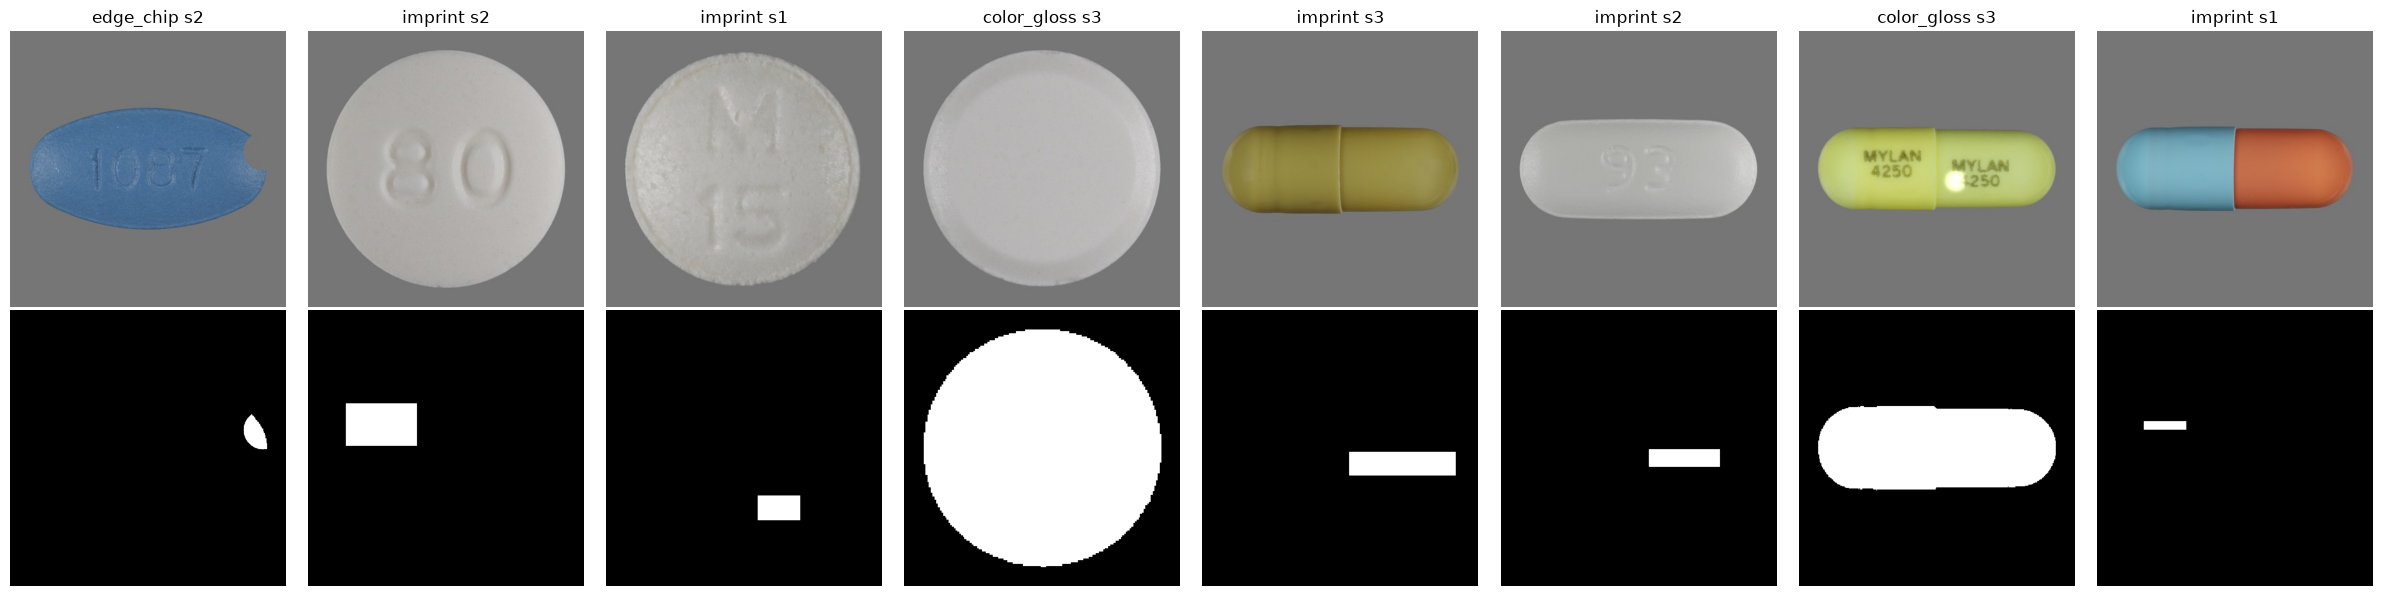

In [22]:
from pv import tamper
types = CFG["tamper_types"][STREAM]; MAX_TAMPER_IMAGES = {"val": 1500, "cal": 1500, "test": 4000}
JPG = PROC / STREAM / "jpg"; MASKS = SYNTH / STREAM / "masks"; TJ = SYNTH / STREAM / "img"
for d in (JPG, MASKS, TJ): d.mkdir(parents=True, exist_ok=True)
if not have(SPLITS / f"{STREAM}_all.csv"):
    rows = []
    for r in tqdm(sp.itertuples(), total=len(sp), desc="genuine re-encode"):
        im = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB); out = JPG / (pathlib.Path(r.path).stem + ".jpg"); tamper.reencode(im, out)
        rows.append(dict(path=str(out), src_path=r.path, obj_mask=r.obj_mask, product_id=r.product_id, group_id=r.group_id, domain=r.domain, split=r.split, label=0, tamper="none", severity=0, mask_path=""))
    gen = pd.DataFrame(rows); trows = []
    for split, cap in MAX_TAMPER_IMAGES.items():
        src = gen[(gen.split == split) & (gen.domain == "phone")]; src = src.sample(min(cap, len(src)), random_state=0)
        for i, r in enumerate(tqdm(src.itertuples(), total=len(src), desc=f"tamper {split}")):
            im = cv2.cvtColor(cv2.imread(r.src_path), cv2.COLOR_BGR2RGB); om = cv2.imread(r.obj_mask, 0) > 0
            for ti, t in enumerate(types):
                sev = (i + ti) % 3 + 1; seed = zlib.crc32(f"{r.src_path}|{t}|{sev}".encode()); o, mk = tamper.apply(t, im, om, sev, seed)
                stem = f"{pathlib.Path(r.src_path).stem}__{t}{sev}"; tamper.reencode(o, TJ / f"{stem}.jpg"); cv2.imwrite(str(MASKS / f"{stem}.png"), mk.astype(np.uint8) * 255)
                trows.append(dict(path=str(TJ / f"{stem}.jpg"), src_path=r.src_path, obj_mask=r.obj_mask, product_id=r.product_id, group_id=r.group_id, domain=r.domain, split=split, label=1, tamper=t, severity=sev, mask_path=str(MASKS / f"{stem}.png")))
    pd.concat([gen, pd.DataFrame(trows)], ignore_index=True).to_csv(SPLITS / f"{STREAM}_all.csv", index=False)
all_df = pd.read_csv(SPLITS / f"{STREAM}_all.csv"); print(all_df.groupby(["split", "label"]).size())
# VISUAL CHECK: wrong-looking tampers = meaningless results
s8 = all_df[all_df.label == 1].sample(8, random_state=1); fig, ax = plt.subplots(2, 8, figsize=(24, 6))
for k, r in enumerate(s8.itertuples()):
    ax[0, k].imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)); ax[0, k].set_title(f"{r.tamper} s{r.severity}"); ax[0, k].axis("off"); ax[1, k].imshow(cv2.imread(r.mask_path, 0), cmap="gray"); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(RES / "figures" / f"tamper_examples_{STREAM}.png", dpi=100); plt.show()

## 4. Capture-quality gate (thresholds fitted on validation genuine phone images only)

In [23]:
from pv import quality
if not have(ROOT / "configs" / f"gate_{STREAM}.json"):
    v = all_df[(all_df.split == "val") & (all_df.label == 0) & (all_df.domain == "phone")].sample(frac=1, random_state=0).head(1500)
    q = pd.DataFrame([quality.quality_metrics(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)) for p in tqdm(v.path)])
    th = quality.fit_thresholds(q, keep=0.95); json.dump(th, open(ROOT / "configs" / f"gate_{STREAM}.json", "w"), indent=1)
    print("pass rate on val genuine:", np.mean([quality.passes(r, th) for r in q.to_dict("records")]))
print(json.load(open(ROOT / "configs" / f"gate_{STREAM}.json")))

{'blur_min': 2.1704256134864566, 'glare_max': 0.0, 'lum_min': 93.39914719920536, 'lum_max': 161.04805908265507}


## 5. Product identification (frozen DINOv2 ViT-S/14, no training; tau set on validation only)

In [24]:
from pv.features import DinoPatch, to_tensor, load_rgb
from pv.metrics import auroc, tpr_at_fpr
from sklearn.metrics import roc_curve
SIZE = 224
if not have(RES / "retrieval" / f"{STREAM}_pred.csv"):
    g = all_df[all_df.label == 0].copy(); dino = DinoPatch(device="cuda")
    @torch.no_grad()
    def embed(paths, rot=0, bs=32):
        out = []
        for i in range(0, len(paths), bs):
            ims = [np.ascontiguousarray(np.rot90(load_rgb(p, SIZE), rot // 90)) for p in paths[i:i+bs]]; _, cls = dino(to_tensor(ims)); out.append(torch.nn.functional.normalize(cls, dim=1).cpu())
        return torch.cat(out)
    gal = g[g.split == "gallery"]; rots = (0, 90, 180, 270) if STREAM == "pill" else (0,)
    G = torch.cat([embed(gal.path.tolist(), r) for r in rots]); Gp = np.tile(gal.product_id.to_numpy(), len(rots)); prods = np.unique(Gp); print(len(prods), "known products")
    def identify(paths):
        Q = embed(paths); S = Q @ G.T; best = np.zeros((len(paths), len(prods)), np.float32)
        for j, p in enumerate(prods): best[:, j] = S[:, torch.from_numpy(Gp == p)].max(1).values.numpy()
        o = np.argsort(-best, 1); return prods[o[:, :5]], np.take_along_axis(best, o[:, :5], 1)
    def run(df_):
        top, sim = identify(df_.path.tolist()); d = df_[["path", "product_id", "split", "domain"]].copy(); d["pred_pid"] = top[:, 0]; d["sim"] = sim[:, 0]; d["top5"] = [";".join(t) for t in top]; return d
    vk = g[(g.split == "val") & (g.domain == "phone")].drop_duplicates("src_path").head(2000); vu = g[(g.split == "unknown_val") & (g.domain == "phone")].head(1000)
    if len(vu) == 0: vu = g[g.split == "unknown_val"].head(1000)
    rk, ru = run(vk), run(vu); print(f"VAL top-1 {(rk.pred_pid == rk.product_id).mean():.3f}  top-5 {np.mean([a in t.split(';') for a, t in zip(rk.product_id, rk.top5)]):.3f}")
    y = np.r_[np.zeros(len(rk)), np.ones(len(ru))]; s = -np.r_[rk.sim, ru.sim]; print("unknown-vs-known AUROC (val):", auroc(y, s))
    f, t, th = roc_curve(y, s); tau = float(-th[np.argmax(t - f)]); json.dump(dict(tau=tau, size=SIZE), open(ROOT / "configs" / f"tau_{STREAM}.json", "w"))
    plt.hist(rk.sim, 40, alpha=.6, label="known (val)"); plt.hist(ru.sim, 40, alpha=.6, label="unknown_val"); plt.axvline(tau, c="k", ls="--", label=f"tau={tau:.2f}"); plt.legend(); plt.xlabel("best cosine similarity"); plt.savefig(RES / "figures" / f"retrieval_tau_{STREAM}.png", dpi=110); plt.show()
    rest = g[(g.split != "gallery") & (g.domain == "phone")]; pred = pd.concat([run(rest.iloc[i:i+2000]) for i in range(0, len(rest), 2000)], ignore_index=True)
    pred["pred_pid_final"] = np.where(pred.sim >= tau, pred.pred_pid, "UNKNOWN"); pred.to_csv(RES / "retrieval" / f"{STREAM}_pred.csv", index=False)
    del dino; torch.cuda.empty_cache()
print("retrieval predictions:", len(pd.read_csv(RES / "retrieval" / f"{STREAM}_pred.csv")))

retrieval predictions: 1280


## 6. Detectors (genuine-only). Tuning on a validation subsample, max 20 configs per method; no test data

In [25]:
from pv.runner import run_method
val_sub = all_df[(all_df.split == "val") & (all_df.domain == "phone")].groupby(["product_id", "label"]).head(6)
tuning_df = pd.concat([all_df[all_df.split == "gallery"], val_sub])
full = all_df[(all_df.split.isin(["gallery", "val", "cal"])) & ((all_df.split == "gallery") | (all_df.domain == "phone"))]
ROT = (0, 90, 180, 270) if STREAM == "pill" else (0,)
tup = lambda c: {k: (list(v) if isinstance(v, tuple) else v) for k, v in c.items()}

def grid_search(cfgs, tag_name):
    out_csv = RES / "tables" / f"grid_{tag_name}_{STREAM}.csv"
    if have(out_csv): return pd.read_csv(out_csv)
    res = []
    for cfg in cfgs:
        info = run_method(cfg, STREAM, tuning_df, splits=("val",), tag="_tune")
        d = pd.read_csv(SCORES / f"{cfg['name']}__{STREAM}__val_tune.csv").dropna(subset=["score"])
        res.append(dict(cfg=json.dumps(tup(cfg)), name=cfg["name"], val_auroc=auroc(d.label, d.score), tpr_at_5fpr=tpr_at_fpr(d.label, d.score, .05), **{k: info[k] for k in ("fit_seconds", "score_seconds_val", "bank_patches_mean")}))
        print(cfg["name"], f"val AUROC {res[-1]['val_auroc']:.3f}")
    t = pd.DataFrame(res).sort_values("val_auroc", ascending=False); t.to_csv(out_csv, index=False); return t

# ---- 6a AnomalyDINO-style (frozen DINOv2 patch matching) ----
cfgs = [dict(name=f"anomalydino_c{i}", kind="dino", ratio=1.0, size=s, topfrac=tf, rotations=r) for i, (s, tf, r) in enumerate(itertools.product([336, 448], [0.005, 0.01, 0.05], [ROT, (0,)]))]
assert len(cfgs) <= CFG["tuning_budget_per_method"]
tab_dino = grid_search(cfgs, "anomalydino")
if not have(SCORES / f"anomalydino_best__{STREAM}__cal.csv"):
    best = json.loads(tab_dino.iloc[0].cfg); best["rotations"] = tuple(best["rotations"]); best["name"] = "anomalydino_best"
    print(run_method(best, STREAM, full, splits=("val", "cal"))); json.dump(tup(best), open(ROOT / "configs" / f"best_anomalydino_{STREAM}.json", "w"), indent=1)
tab_dino.head()

,cfg,name,val_auroc,tpr_at_5fpr,fit_seconds,score_seconds_val,bank_patches_mean
0,"{""name"": ""anomalydino_c8"", ""kind"": ""dino"", ""ra...",anomalydino_c8,0.749896,0.418919,1488.450082,207.688905,8669.866667
1,"{""name"": ""anomalydino_c6"", ""kind"": ""dino"", ""ra...",anomalydino_c6,0.749030,0.405405,105.228656,238.506016,8669.866667
2,"{""name"": ""anomalydino_c2"", ""kind"": ""dino"", ""ra...",anomalydino_c2,0.727239,0.376126,61.666482,9.959281,4876.800000
3,"{""name"": ""anomalydino_c0"", ""kind"": ""dino"", ""ra...",anomalydino_c0,0.715784,0.328829,61.623577,10.491013,4876.800000
4,"{""name"": ""anomalydino_c4"", ""kind"": ""dino"", ""ra...",anomalydino_c4,0.711443,0.351351,62.149622,10.670497,4876.800000


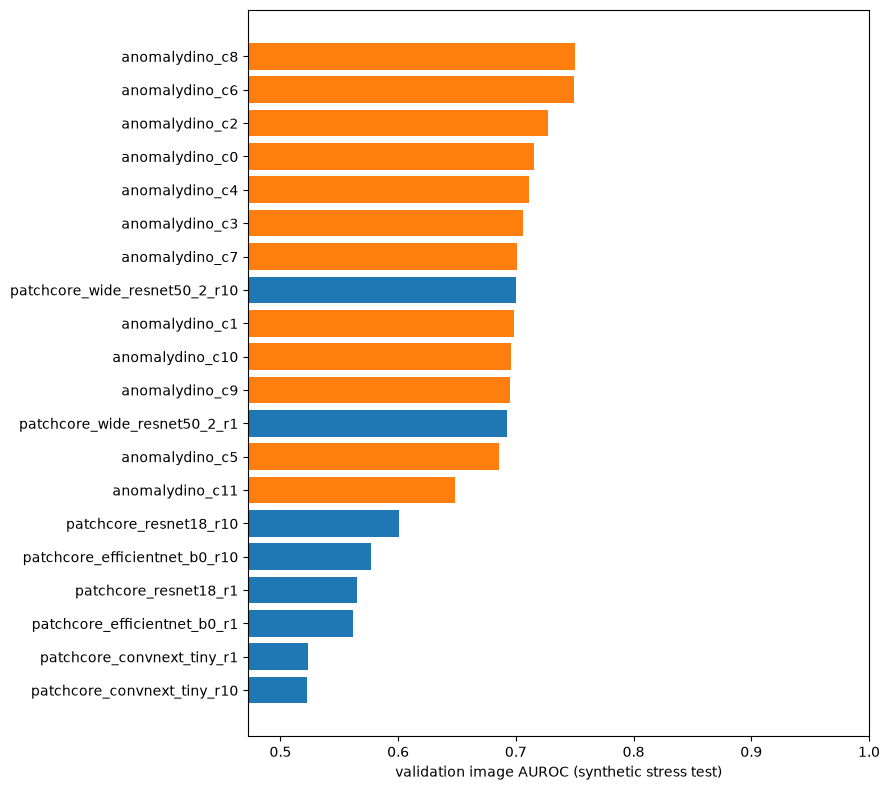

,cfg,name,val_auroc,tpr_at_5fpr,fit_seconds,score_seconds_val,bank_patches_mean
0,"{""name"": ""patchcore_wide_resnet50_2_r10"", ""kin...",patchcore_wide_resnet50_2_r10,0.700167,0.373874,124.880601,4.800052,866.777083
1,"{""name"": ""patchcore_wide_resnet50_2_r1"", ""kind...",patchcore_wide_resnet50_2_r1,0.692836,0.364865,41.242799,4.857977,85.783333
2,"{""name"": ""patchcore_resnet18_r10"", ""kind"": ""cn...",patchcore_resnet18_r10,0.601008,0.193919,123.089843,3.058595,866.777083
3,"{""name"": ""patchcore_efficientnet_b0_r10"", ""kin...",patchcore_efficientnet_b0_r10,0.577367,0.105856,134.598233,6.104334,866.777083
4,"{""name"": ""patchcore_resnet18_r1"", ""kind"": ""cnn...",patchcore_resnet18_r1,0.565196,0.094595,47.167055,4.125432,85.783333
5,"{""name"": ""patchcore_efficientnet_b0_r1"", ""kind...",patchcore_efficientnet_b0_r1,0.561706,0.101351,51.268328,5.913049,85.783333
6,"{""name"": ""patchcore_convnext_tiny_r1"", ""kind"":...",patchcore_convnext_tiny_r1,0.523477,0.051802,43.872701,4.292339,85.783333
7,"{""name"": ""patchcore_convnext_tiny_r10"", ""kind""...",patchcore_convnext_tiny_r10,0.522537,0.051802,120.445237,4.225435,866.777083


In [26]:
# ---- 6b PatchCore backbone comparison (CNN baseline); bank size + timing recorded ----
cfgs = [dict(name=f"patchcore_{b}_r{int(r*100)}", kind="cnn", size=256, topfrac=0.0, rotations=ROT, out_dim=512, backbone=b, ratio=r)
        for b, r in itertools.product(["resnet18", "wide_resnet50_2", "efficientnet_b0", "convnext_tiny"], [0.01, 0.10])]
tab_pc = grid_search(cfgs, "patchcore")
if not have(SCORES / f"patchcore_best__{STREAM}__cal.csv"):
    best = json.loads(tab_pc.iloc[0].cfg); best["rotations"] = tuple(best["rotations"])
    for sd in CFG["seeds"]: run_method(dict(best, name="patchcore_best"), STREAM, full, splits=("val", "cal"), seed=sd, tag=f"_seed{sd}")
    cfg = dict(best, name="patchcore_best"); run_method(cfg, STREAM, full, splits=("val", "cal"), seed=0); json.dump(tup(cfg), open(ROOT / "configs" / f"best_patchcore_{STREAM}.json", "w"), indent=1)
# visual: detector/backbone comparison on validation
allg = pd.concat([tab_dino.assign(family="AnomalyDINO"), tab_pc.assign(family="PatchCore")]).sort_values("val_auroc")
plt.figure(figsize=(9, 0.35 * len(allg) + 1)); plt.barh(allg.name, allg.val_auroc, color=["tab:orange" if f == "AnomalyDINO" else "tab:blue" for f in allg.family]); plt.xlim(max(0.4, allg.val_auroc.min() - .05), 1); plt.xlabel("validation image AUROC (synthetic stress test)")
plt.tight_layout(); plt.savefig(RES / "figures" / f"grid_comparison_{STREAM}.png", dpi=110); plt.show(); tab_pc

In [27]:
import pathlib
if not getattr(pathlib.Path, "_symlink_patched", False):
    _orig_symlink = pathlib.Path.symlink_to
    def _safe_symlink(self, target, target_is_directory=False):
        try: _orig_symlink(self, target, target_is_directory)
        except OSError: pass
    pathlib.Path.symlink_to = _safe_symlink
    pathlib.Path._symlink_patched = True

In [28]:
import numpy as np
# --- NumPy 2.x compatibility for old libs (imgaug / anomalib 1.2.0); in-memory only ---
if not hasattr(np, "sctypes"):
    np.sctypes = {"int": [np.int8, np.int16, np.int32, np.int64], "uint": [np.uint8, np.uint16, np.uint32, np.uint64],
                  "float": [np.float16, np.float32, np.float64], "complex": [np.complex64, np.complex128],
                  "others": [bool, object, bytes, str, np.void]}
for _n, _t in (("int", int), ("float", float), ("complex", complex), ("object", object), ("str", str), ("bool", bool)):
    if _n not in np.__dict__: setattr(np, _n, _t)

import importlib.util
_need = ("anomalib", "albumentations", "lightning", "imgaug")
_missing = [m for m in _need if importlib.util.find_spec(m) is None]
if RUN_EFFICIENTAD and _missing:
    print("missing packages, skipping EfficientAD:", _missing, "-> pip install", " ".join(_missing)); RUN_EFFICIENTAD = False

# ---- 6c EfficientAD (trained, anomalib==1.2.0) ----
name_e = f"efficientad_{EFFAD_SIZE.lower()}"; ckpt = ROOT / "models" / f"{name_e}_{STREAM}_s{SEED}.pt"
val_csv = SCORES / f"{name_e}__{STREAM}__val_seed{SEED}.csv"; cal_csv = SCORES / f"{name_e}__{STREAM}__cal_seed{SEED}.csv"
min_txt = ckpt.with_suffix(".min"); effad = None
if RUN_EFFICIENTAD:
    from anomalib import TaskType
    from anomalib.models import EfficientAd
    from anomalib.models.image.efficient_ad.torch_model import EfficientAdModelSize
    _size = EfficientAdModelSize.S if EFFAD_SIZE == "S" else EfficientAdModelSize.M

if RUN_EFFICIENTAD and not have(ckpt):
    import albumentations as A
    from anomalib.data import Folder
    from anomalib.engine import Engine
    from lightning.pytorch import seed_everything as pl_seed
    D = ROOT / "data" / "anomalib" / STREAM
    for s_ in ("train/good", "val/good", "val/bad"): (D / s_).mkdir(parents=True, exist_ok=True)
    aug = A.Compose([A.RandomBrightnessContrast(.25, .25, p=.8), A.HueSaturationValue(8, 20, 15, p=.6), A.GaussianBlur((3, 5), p=.3), A.Rotate(limit=10, border_mode=cv2.BORDER_REPLICATE, p=.5), A.ImageCompression(quality_range=(70, 95), p=.4)])
    gal_ = all_df[all_df.split == "gallery"]
    n_have = len(list((D / "train/good").glob("*.jpg")))
    if n_have >= len(gal_) * 9: print(f"train/good already has {n_have} images - skipping write")
    else:
        for i, r in enumerate(tqdm(gal_.itertuples(), total=len(gal_), desc="train/good")):
            im = cv2.imread(r.path); cv2.imwrite(str(D / "train/good" / f"{i}_orig.jpg"), im)
            for k in range(8):
                a = aug(image=cv2.cvtColor(np.ascontiguousarray(np.rot90(im, k % 4)), cv2.COLOR_BGR2RGB))["image"]; cv2.imwrite(str(D / "train/good" / f"{i}_a{k}.jpg"), cv2.cvtColor(a, cv2.COLOR_RGB2BGR))
    for f_ in list((D / "val/good").glob("*.jpg")) + list((D / "val/bad").glob("*.jpg")): f_.unlink()
    for i, r in enumerate(val_sub.itertuples()): shutil.copy(r.path, D / ("val/bad" if r.label else "val/good") / f"{i}.jpg")
    pl_seed(SEED)
    dm = Folder(name=f"pv_{STREAM}", root=str(D), normal_dir="train/good", abnormal_dir="val/bad", normal_test_dir="val/good",
                task=TaskType.CLASSIFICATION, image_size=(256, 256), train_batch_size=1, eval_batch_size=8, num_workers=0)
    effad = EfficientAd(model_size=_size)
    engine = Engine(task=TaskType.CLASSIFICATION, max_steps=EFFAD_STEPS, max_epochs=-1, accelerator="gpu", devices=1,
                    default_root_dir=str(RES / "logs" / f"{name_e}_{STREAM}_s{SEED}"), check_val_every_n_epoch=None,
                    val_check_interval=min(5000, EFFAD_STEPS), enable_progress_bar=False)
    t0 = time.time(); engine.fit(model=effad, datamodule=dm); train_min = (time.time() - t0) / 60; print(f"trained in {train_min:.1f} min")
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    torch.save(effad.state_dict(), ckpt); min_txt.write_text(str(train_min)); print("checkpoint saved:", ckpt)
else: print("EfficientAD training skipped (disabled or checkpoint exists):", ckpt)

if RUN_EFFICIENTAD and not (have(val_csv) and have(cal_csv)):
    if effad is None:
        effad = EfficientAd(model_size=_size); effad.load_state_dict(torch.load(ckpt, map_location="cpu"))
    net = effad.model.eval().cuda(); tf = getattr(effad, "_transform", None)
    train_min = float(min_txt.read_text()) if have(min_txt) else float("nan")
    @torch.no_grad()
    def eff_score(path):
        x = to_tensor([load_rgb(path, 256)])
        if tf is not None: x = tf(x)
        x = x.cuda()
        try: o = net(x, normalize=False)
        except TypeError: o = net(x)
        if isinstance(o, dict): s = o.get("pred_score", None)
        elif hasattr(o, "pred_score"): s = o.pred_score
        else: s = o[0]
        if s is None: s = o["anomaly_map"].amax()
        return float(torch.as_tensor(s).max())
    for sp_ in ("val", "cal"):
        d = all_df[(all_df.split == sp_) & (all_df.domain == "phone")].copy(); d["score"] = [eff_score(p) for p in tqdm(d.path)]
        d.to_csv(SCORES / f"{name_e}__{STREAM}__{sp_}_seed{SEED}.csv", index=False)
        if sp_ == "val": va = auroc(d.label, d.score); print("VAL AUROC", va)
    pd.DataFrame([dict(model=name_e, stream=STREAM, seed=SEED, steps=EFFAD_STEPS, train_minutes=train_min, val_auroc=va)]).to_csv(RES / "tables" / f"effad_{EFFAD_SIZE}_{STREAM}_s{SEED}.csv", index=False)
    del net, effad; torch.cuda.empty_cache()
else: print("EfficientAD scoring skipped (disabled or CSVs exist)")

EfficientAD training skipped (disabled or checkpoint exists): D:\pharmavaluate\models\efficientad_s_pill_s0.pt
EfficientAD scoring skipped (disabled or CSVs exist)


## 8. Pick winner, Mondrian conformal calibration, FREEZE
Winner = best **validation** image AUROC across the patch-method grids (tie-break TPR@5%FPR). `alpha_gen` is chosen on calibration *synthetic* tampers - this gives **no guarantee on real counterfeits**.

             name  val_auroc  tpr_at_5fpr
0  anomalydino_c8   0.749896     0.418919
1  anomalydino_c6   0.749030     0.405405
2  anomalydino_c2   0.727239     0.376126
3  anomalydino_c0   0.715784     0.328829
4  anomalydino_c4   0.711443     0.351351
WINNER: anomalydino_c8
260 calibration genuine; need >= 99 for alpha_cf = 0.01
alpha_gen = 0.5 | cal tampers with p<=alpha_cf: 0.09615384615384616


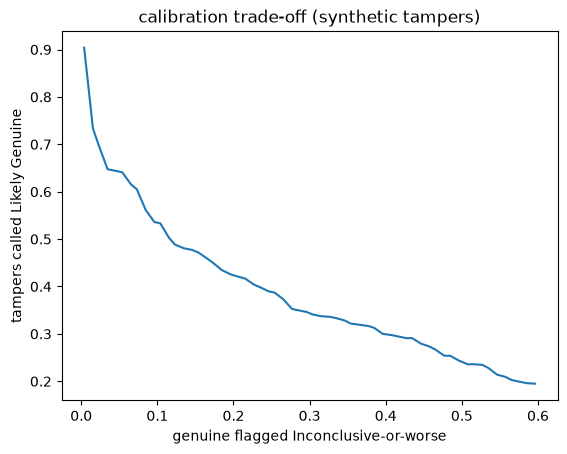

FROZEN. Commit configs/frozen.yaml and git tag it before section 9.


In [29]:
from pv.conformal import Mondrian, pvalues, min_cal_size, decide, fuse
grids = pd.concat([pd.read_csv(f) for f in glob.glob(str(RES / "tables" / f"grid_*_{STREAM}.csv"))]).sort_values(["val_auroc", "tpr_at_5fpr"], ascending=False)
print(grids[["name", "val_auroc", "tpr_at_5fpr"]].head(5).to_string()); winner_cfg = json.loads(grids.iloc[0].cfg); print("WINNER:", winner_cfg["name"])
family = "anomalydino" if winner_cfg["name"].startswith("anomalydino") else "patchcore"
cal = pd.read_csv(SCORES / f"{family}_best__{STREAM}__cal.csv").dropna(subset=["score"])
cal_gen = cal[(cal.label == 0) & (cal.domain == "phone")].copy(); cal_gen["stream"] = STREAM; cal_tam = cal[cal.label == 1]
print(len(cal_gen), "calibration genuine; need >=", min_cal_size(CFG["alpha_cf"]), "for alpha_cf =", CFG["alpha_cf"])
mon = Mondrian().fit(cal_gen); cells = mon.cells[(STREAM, "phone")]
p_t = pvalues(cells, cal_tam.score.to_numpy()); alpha_gen = float(np.quantile(p_t, 0.95)); alpha_gen = min(max(alpha_gen, CFG["alpha_cf"] * 2), 0.5)
print("alpha_gen =", alpha_gen, "| cal tampers with p<=alpha_cf:", (p_t <= CFG["alpha_cf"]).mean())
al = np.linspace(0.01, 0.6, 60); p_g = pvalues(cells, cal_gen.score.to_numpy())
plt.plot([(p_g <= a).mean() for a in al], [(p_t > a).mean() for a in al]); plt.xlabel("genuine flagged Inconclusive-or-worse"); plt.ylabel("tampers called Likely Genuine"); plt.title("calibration trade-off (synthetic tampers)")
plt.savefig(RES / "figures" / f"coverage_error_{STREAM}.png", dpi=110); plt.show()
fp_ = ROOT / "configs" / "frozen.yaml"; frozen = yaml.safe_load(open(fp_)) if have(fp_) else {}
frozen[STREAM] = dict(method_cfg=winner_cfg, cal_scores=[float(x) for x in np.sort(cells)], alpha_cf=CFG["alpha_cf"], alpha_gen=alpha_gen,
    tau=json.load(open(ROOT / "configs" / f"tau_{STREAM}.json"))["tau"], gate=json.load(open(ROOT / "configs" / f"gate_{STREAM}.json")))
yaml.safe_dump(frozen, open(fp_, "w")); print("FROZEN. Commit configs/frozen.yaml and git tag it before section 9.")

## 9. FINAL TEST - run once, only after freezing (set `I_FROZE_EVERYTHING = True` in section 0)

In [30]:
assert I_FROZE_EVERYTHING, "Set I_FROZE_EVERYTHING = True in section 0 only after frozen.yaml is written and committed."
from pv.metrics import cluster_bootstrap
fz = yaml.safe_load(open(ROOT / "configs" / "frozen.yaml")); out = {}
for stream in [s for s in ("pill", "pack") if s in fz]:
    f = fz[stream]; cfg = f["method_cfg"]; cfg["rotations"] = tuple(cfg.get("rotations", (0,))); a_df = pd.read_csv(SPLITS / f"{stream}_all.csv")
    sub = a_df[(a_df.split == "gallery") | ((a_df.split == "test") & (a_df.domain == "phone"))]; run_method(cfg, stream, sub, splits=("test",), tag="_FINAL")
    ret = pd.read_csv(RES / "retrieval" / f"{stream}_pred.csv"); e2e = a_df.merge(ret[["path", "pred_pid_final"]], on="path", how="inner")
    e2e = e2e[((e2e.split == "test") | (e2e.split == "unknown_test")) & (e2e.label == 0)]
    e2e = pd.concat([a_df[a_df.split == "gallery"].assign(pred_pid_final=lambda d: d.product_id), e2e]); run_method(cfg, stream, e2e, splits=("test", "unknown_test"), pid_col="pred_pid_final", tag="_E2E_FINAL"); out[stream] = f
def load(stream, tag, sp_): return pd.read_csv(SCORES / f"{fz[stream]['method_cfg']['name']}__{stream}__{sp_}{tag}.csv")
rows = []
for stream, f in out.items():
    cal_ = np.array(f["cal_scores"]); acf, agen = f["alpha_cf"], f["alpha_gen"]
    t = load(stream, "_FINAL", "test").dropna(subset=["score"]); t["p"] = pvalues(cal_, t.score.to_numpy()); g = t[t.label == 0]
    m_, lo_, hi_ = cluster_bootstrap(g.assign(label=0), lambda d: (d.p <= acf).mean(), n=500)
    rows += [dict(test="T1", stream=stream, metric=f"false Likely-Counterfeit rate (target <= {acf})", value=(g.p <= acf).mean(), ci_lo=lo_, ci_hi=hi_),
             dict(test="T1", stream=stream, metric="Inconclusive-or-worse rate on genuine", value=(g.p <= agen).mean(), ci_lo=np.nan, ci_hi=np.nan)]
    for (tt, sv), d in t[t.label == 1].groupby(["tamper", "severity"]):
        rows.append(dict(test="T3", stream=stream, metric=f"AUROC {tt} sev{sv} (synthetic stress test)", value=auroc(pd.concat([g, d]).label, pd.concat([g, d]).score), ci_lo=np.nan, ci_hi=np.nan))
    m_, lo_, hi_ = cluster_bootstrap(t, lambda d: auroc(d.label, d.score), n=300)
    rows += [dict(test="T3", stream=stream, metric="AUROC all tampers (synthetic stress test)", value=m_, ci_lo=lo_, ci_hi=hi_), dict(test="T3", stream=stream, metric="TPR@5%FPR", value=tpr_at_fpr(t.label, t.score, .05), ci_lo=np.nan, ci_hi=np.nan)]
    u = load(stream, "_E2E_FINAL", "unknown_test"); u_rej = (u.pred_pid_final == "UNKNOWN").mean() if "pred_pid_final" in u else np.nan
    us = u.dropna(subset=["score"]); u_fc = (pvalues(cal_, us.score.to_numpy()) <= acf).sum() / max(len(u), 1)
    rows += [dict(test="T2", stream=stream, metric="Unknown-product rejection rate", value=u_rej, ci_lo=np.nan, ci_hi=np.nan), dict(test="T2", stream=stream, metric="Unknown products wrongly called Likely Counterfeit", value=u_fc, ci_lo=np.nan, ci_hi=np.nan)]
    ret = pd.read_csv(RES / "retrieval" / f"{stream}_pred.csv"); k = ret[ret.split == "test"]
    rows += [dict(test="T6", stream=stream, metric="identification top-1 (test)", value=(k.pred_pid == k.product_id).mean(), ci_lo=np.nan, ci_hi=np.nan),
             dict(test="T6", stream=stream, metric="identification top-5 (test)", value=np.mean([a in s.split(";") for a, s in zip(k.product_id, k.top5)]), ci_lo=np.nan, ci_hi=np.nan)]
final = pd.DataFrame(rows); final.to_csv(RES / "tables" / "FINAL_tests.csv", index=False); print(final.to_string())

Using cache found in C:\Users\Soubh/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\Soubh/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\Soubh/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\Soubh/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
scoring: 100%|██████████| 2476/2476 [01:10<00:00, 35.35it/s]
Using cache found in C:\Users\Soubh/.cache\torch\hub\facebookresearch_dinov2_main
scoring: 100%|██████████| 126/126 [00:04<00:00, 29.37it/s]


   test stream                                              metric     value     ci_lo     ci_hi
0    T1   pill      false Likely-Counterfeit rate (target <= 0.01)  0.003231  0.000000  0.008198
1    T1   pill               Inconclusive-or-worse rate on genuine  0.523425       NaN       NaN
2    T3   pill      AUROC color_gloss sev1 (synthetic stress test)  0.512767       NaN       NaN
3    T3   pill      AUROC color_gloss sev2 (synthetic stress test)  0.716708       NaN       NaN
4    T3   pill      AUROC color_gloss sev3 (synthetic stress test)  0.813534       NaN       NaN
5    T3   pill        AUROC edge_chip sev1 (synthetic stress test)  0.932541       NaN       NaN
6    T3   pill        AUROC edge_chip sev2 (synthetic stress test)  0.969988       NaN       NaN
7    T3   pill        AUROC edge_chip sev3 (synthetic stress test)  0.967947       NaN       NaN
8    T3   pill          AUROC imprint sev1 (synthetic stress test)  0.493019       NaN       NaN
9    T3   pill          AUROC 

## 10. Final plots (read from saved score files; synthetic tampers = stress test, not real counterfeits)

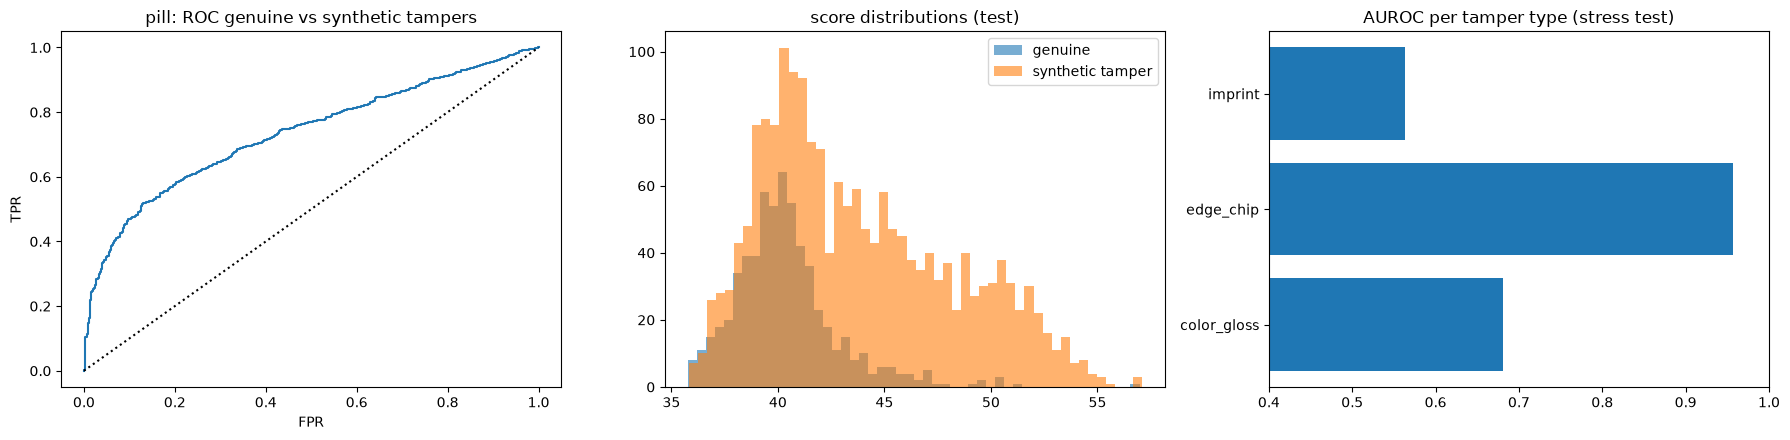

Decision counts on test (screening only, verify manually):
genuine           Inconclusive           322
                  Likely Genuine         295
                  Likely Counterfeit       2
synthetic tamper  Inconclusive          1279
                  Likely Genuine         415
                  Likely Counterfeit     163
Name: count, dtype: int64


In [31]:
for stream, f in out.items():
    cal_ = np.array(f["cal_scores"]); t = load(stream, "_FINAL", "test").dropna(subset=["score"]); t["p"] = pvalues(cal_, t.score.to_numpy())
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    fpr, tpr, _ = roc_curve(t.label, t.score); ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title(f"{stream}: ROC genuine vs synthetic tampers"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
    ax[1].hist(t[t.label == 0].score, 50, alpha=.6, label="genuine"); ax[1].hist(t[t.label == 1].score, 50, alpha=.6, label="synthetic tamper"); ax[1].legend(); ax[1].set_title("score distributions (test)")
    g = t[t.label == 0]; per = {tt: auroc(pd.concat([g, d]).label, pd.concat([g, d]).score) for tt, d in t[t.label == 1].groupby("tamper")}
    ax[2].barh(list(per), list(per.values())); ax[2].set_xlim(.4, 1); ax[2].set_title("AUROC per tamper type (stress test)")
    plt.tight_layout(); plt.savefig(RES / "figures" / f"final_{stream}.png", dpi=110); plt.show()
    print("Decision counts on test (screening only, verify manually):"); print(pd.Series(["Likely Counterfeit" if p <= f["alpha_cf"] else "Inconclusive" if p <= f["alpha_gen"] else "Likely Genuine" for p in t.p]).groupby(t.label.map({0: "genuine", 1: "synthetic tamper"}).values).value_counts())